# 留存与复购

回答：用户第一次来之后还会不会回来？多久回来一次？买过的人会买第二次吗？

**口径**：
- 首活日（T0）= 用户在 9 天窗口内第一次出现行为的日期
- N 日留存 = 首活日后第 N 天仍有行为的用户数 / 该日新增用户数
- 窗口只有 9 天，所以早期队列能看到 D8，后面几天的队列只能看到 D1、D2

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

## 1. 读取数据

In [2]:
data = pd.read_csv(
    'data/UserBehavior_clean.csv',
    usecols=['user_id', 'behavior_type', 'timestamp'],
    dtype={'user_id': 'int32', 'behavior_type': 'category', 'timestamp': 'int64'},
    encoding='utf-8-sig',
)
data['day_idx'] = pd.to_datetime(data['timestamp'] + 8 * 3600, unit='s').dt.day_of_year.astype('int16')
data['is_buy'] = (data['behavior_type'] == 'buy').astype('int8')
data = data.drop(columns=['timestamp', 'behavior_type'])
print(data.shape)
data.head()

(100095231, 3)


,user_id,day_idx,is_buy
0,1,329,0
1,1,329,0
2,1,329,0
3,1,329,0
4,1,329,0


## 2. 构造「用户 × 天」表

留存只需要知道「某天有没有来过 / 有没有买」，所以先把 1 亿行压成用户-天粒度，后面所有计算都在小表上做。

In [3]:
# 每个用户的首活日
first_day = data.groupby('user_id')['day_idx'].min().rename('first_day')

# 用户 × 天：是否购买（来过就是一行）
ud = data.groupby(['user_id', 'day_idx'], observed=True).agg(is_buy=('is_buy', 'max')).reset_index()
ud = ud.merge(first_day, on='user_id', how='left')
ud['offset'] = (ud['day_idx'] - ud['first_day']).astype('int8')

del data   # 释放 1 亿行的大表
print('用户-天行数:', len(ud))
print('用户数:', ud['user_id'].nunique())
ud.head()

用户-天行数: 6968544
用户数: 987991


,user_id,day_idx,is_buy,first_day,offset
0,1,329,0,329,0
1,1,330,0,329,1
2,1,331,0,329,2
3,1,332,0,329,3
4,1,333,0,329,4


## 3. 留存矩阵

行是首活日队列，列是第 N 天，值是该队列在第 N 天回访的比例。
空白表示窗口不够（比如 12-03 的队列看不到 D2）。

In [4]:
cohort_size = ud.groupby('first_day')['user_id'].nunique()
active = ud.groupby(['first_day', 'offset'])['user_id'].nunique().unstack()
retention = (active.div(cohort_size, axis=0) * 100).round(1)

date_label = lambda d: (pd.Timestamp('2017-01-01') + pd.Timedelta(days=int(d) - 1)).strftime('%m-%d')
retention.index = [f'{date_label(d)}（{cohort_size[d]:,}人）' for d in retention.index]
retention

offset,0,1,2,3,4,5,6,7,8
"11-25（706,641人）",100.0,78.9,76.8,75.9,76.1,76.6,77.3,98.6,98.3
"11-26（158,188人）",100.0,65.4,64.6,65.9,66.9,68.6,97.8,97.4,NaN
"11-27（63,825人）",100.0,61.5,62.4,64.4,66.3,97.2,96.7,NaN,NaN
"11-28（31,331人）",100.0,61.8,63.7,66.4,96.8,96.2,NaN,NaN,NaN
"11-29（17,931人）",100.0,69.8,72.0,96.6,96.0,NaN,NaN,NaN,NaN
"11-30（9,801人）",100.0,94.6,95.8,95.3,NaN,NaN,NaN,NaN,NaN
12-01（255人）,100.0,90.2,92.9,NaN,NaN,NaN,NaN,NaN,NaN
12-02（18人）,100.0,72.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12-03（1人）,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


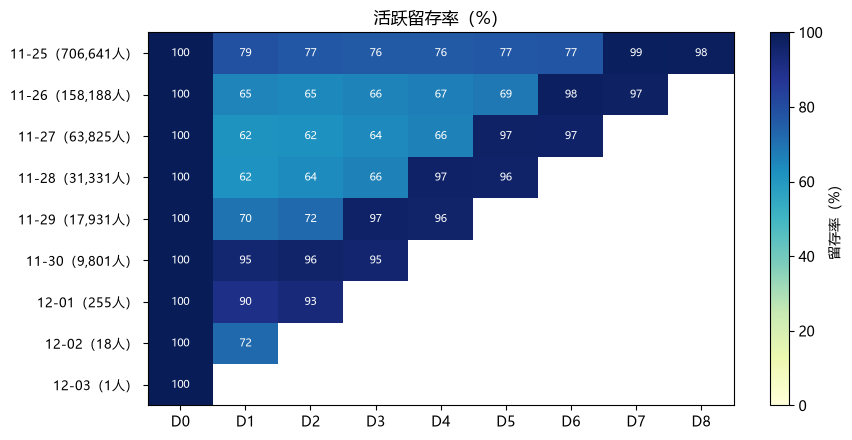

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
im = ax.imshow(retention.values, aspect='auto', cmap='YlGnBu', vmin=0, vmax=100)
ax.set_xticks(range(retention.shape[1]))
ax.set_xticklabels([f'D{c}' for c in retention.columns])
ax.set_yticks(range(len(retention)))
ax.set_yticklabels(retention.index, fontsize=9)
ax.set_title('活跃留存率（%）')

for i in range(retention.shape[0]):
    for j in range(retention.shape[1]):
        v = retention.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=8,
                    color='white' if v > 50 else 'black')

plt.colorbar(im, ax=ax, label='留存率（%）')
plt.tight_layout()
plt.show()

## 3.1 异常诊断：这份数据能做留存吗？

上面的矩阵有个明显反常：**11-25 队列的 D7、D8 几乎是 100%，11-30 队列的 D1 是 94.6%**。
留存曲线应该是单调衰减的，不会突然回到 100%。

怀疑不是留存真的高，而是每天覆盖的用户范围不同 —— 用「每天活跃用户数 / 全量用户数」验证一下。

In [6]:
total_users = ud['user_id'].nunique()
uv_day = ud.groupby('day_idx')['user_id'].nunique()
coverage = pd.DataFrame({
    '当日活跃用户': uv_day,
    '占全量用户(%)': (uv_day / total_users * 100).round(1),
})
coverage.index = [date_label(d) for d in coverage.index]
coverage

,当日活跃用户,占全量用户(%)
11-25,706641,71.5
11-26,715516,72.4
11-27,710094,71.9
11-28,709257,71.8
11-29,718922,72.8
11-30,730597,73.9
12-01,740139,74.9
12-02,970401,98.2
12-03,966977,97.9


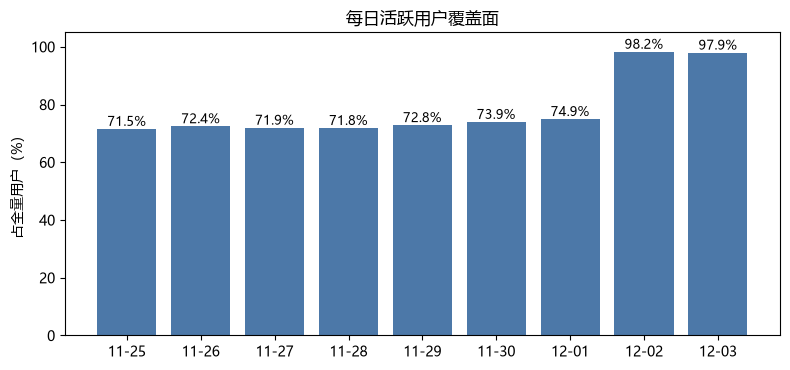

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(coverage.index, coverage['占全量用户(%)'], color='#4C78A8')
ax.set_ylim(0, 105)
ax.set_ylabel('占全量用户（%）')
ax.set_title('每日活跃用户覆盖面')
for i, v in enumerate(coverage['占全量用户(%)']):
    ax.text(i, v, f'{v}%', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

结论很清楚：**12-02、12-03 两天几乎覆盖了全部用户（约 98%）**，而前面几天只有 70% 左右。

说明这份数据不是「均匀采集 9 天」，而是以最后两天为锚点、补齐了用户此前几天的历史行为。
这会让任何跨天回访指标失真 —— 所以下面的购买留存和复购率**只能作为口径演示，不能当业务结论**。

## 4. 购买留存

把分子换成「当天有购买」，看买过的人之后还会不会继续买。
（注意上面说的采集偏差，这里的数值会偏高）

In [8]:
buy_active = ud[ud['is_buy'] == 1].groupby(['first_day', 'offset'])['user_id'].nunique().unstack()
buy_retention = (buy_active.div(cohort_size, axis=0) * 100).round(1)
buy_retention.index = [date_label(d) for d in buy_retention.index]
buy_retention

offset,0,1,2,3,4,5,6,7,8
11-25,18.8,15.7,16.4,15.2,15.6,15.3,14.5,17.7,17.7
11-26,16.0,12.7,12.2,12.9,13.1,12.9,17.4,17.2,NaN
11-27,17.1,12.1,12.5,12.9,13.0,17.5,17.1,NaN,NaN
11-28,18.1,13.0,12.5,13.0,17.9,16.7,NaN,NaN,NaN
11-29,20.8,15.0,15.0,18.1,17.0,NaN,NaN,NaN,NaN
11-30,23.8,21.1,19.3,17.4,NaN,NaN,NaN,NaN,NaN
12-01,30.2,13.7,19.2,NaN,NaN,NaN,NaN,NaN,NaN
12-02,50.0,11.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12-03,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. 复购率与复购间隔

复购按**天**判定：不同日期各买过一次才算复购（同一天买多次不算）。

In [9]:
buy_days = ud[ud['is_buy'] == 1].groupby('user_id')['day_idx'].nunique()
buyers = len(buy_days)
repeat_buyers = int((buy_days >= 2).sum())

print(f'购买用户 {buyers:,} 人，其中复购 {repeat_buyers:,} 人，复购率 {repeat_buyers / buyers * 100:.2f}%')
print('\n购买天数分布:')
print(buy_days.value_counts().sort_index())

购买用户 672,404 人，其中复购 370,274 人，复购率 55.07%

购买天数分布:
day_idx
1    302130
2    196830
3    100103
4     44244
5     18066
6      6979
7      2633
8      1001
9       418
Name: count, dtype: int64


In [10]:
bd = ud[ud['is_buy'] == 1].sort_values(['user_id', 'day_idx'])
bd['gap'] = bd.groupby('user_id')['day_idx'].diff()
gap = bd['gap'].dropna().astype(int)

print(f'复购间隔：中位数 {gap.median():.0f} 天，平均 {gap.mean():.1f} 天')
gap.value_counts().sort_index().to_frame('复购次数')

复购间隔：中位数 2 天，平均 2.4 天


,复购次数
gap,
1,277994
2,148726
3,92269
4,59947
5,38234
6,25110
7,15110
8,5686


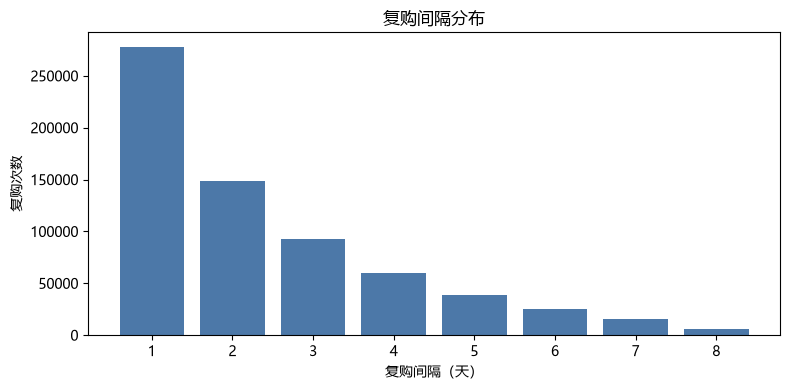

In [11]:
vc = gap.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(vc.index, vc.values, color='#4C78A8')
ax.set_xlabel('复购间隔（天）')
ax.set_ylabel('复购次数')
ax.set_title('复购间隔分布')
ax.set_xticks(vc.index)
plt.tight_layout()
plt.show()

## 结论

**1. 留存分析在这份数据上不成立。**
矩阵里 11-25 队列的 D7、D8 高达 98%，明显违背「留存单调衰减」的常识。
诊断后确认原因：12-02、12-03 两天覆盖了全量用户的约 98%，而前 7 天只有 70% 左右——
数据不是均匀采集 9 天，而是以最后两天为锚点补齐了用户的历史行为。

**2. 复购数字同样被污染。**
购买用户 67.2 万，其中 37.0 万在不同日期买过至少两次，复购率 55.07%；复购间隔中位数 2 天。
这两个数看起来很高，但本质上是「最后两天全员在场 + 历史行为补齐」造成的，不能当业务结论。

**3. 这份数据能做什么、不能做什么。**
- 能做：日内时段规律、行为结构、品类/商品对比、漏斗形状（这些不依赖跨天回访）
- 不能做：留存曲线、复购率、生命周期、长期趋势

**4. 方法论收获**：做留存前先检查「每日活跃用户覆盖面」是否一致。
如果各天覆盖的人群范围不同，Cohort 留存会被系统性地扭曲——这一步检查比算留存本身更重要。